<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_16_Softmax_Probability_Distributions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

from transformers import AutoModelForCausalLM, GPT2Tokenizer

# Part 1: Softmax in NumPy and PyTorch


## Task_1:
- Transform the following list of numbers into a softmax distribution
by translating Equation 4.8 into NumPy code. Print the softmax
probabilities and confirm that they sum to 1.
z = [1,1.1,2,3,5,6,6.1]
Repeat the calculation using PyTorch’s softmax function. Be
mindful of datatypes. Print out the softmax probabilities and
confirm that they match the NumPy output.
Show both results in a graph as in Figure 4.2.

In [5]:
z = [1,1.1,2,3,5,6,6.1]
def softmax(z):
    z = np.asarray(z, dtype=np.float64)
    z = z - np.max(z)
    exp_z = np.exp(z)
    return exp_z / np.sum(exp_z)
softmax(z)

array([0.00263681, 0.00291413, 0.0071676 , 0.01948356, 0.1439651 ,
       0.39133772, 0.43249507])

In [3]:
zTorch = torch.tensor(z,dtype=torch.float32)

# using a function
zTorch_sm = F.softmax(zTorch,dim=-1)
zTorch_sm

tensor([0.0026, 0.0029, 0.0072, 0.0195, 0.1440, 0.3913, 0.4325])

In [6]:
num = np.exp(z)
den = np.sum( np.exp(z) )
sm = num / den

print(sm)
print(np.sum(sm))

[0.00263681 0.00291413 0.0071676  0.01948356 0.1439651  0.39133772
 0.43249507]
1.0


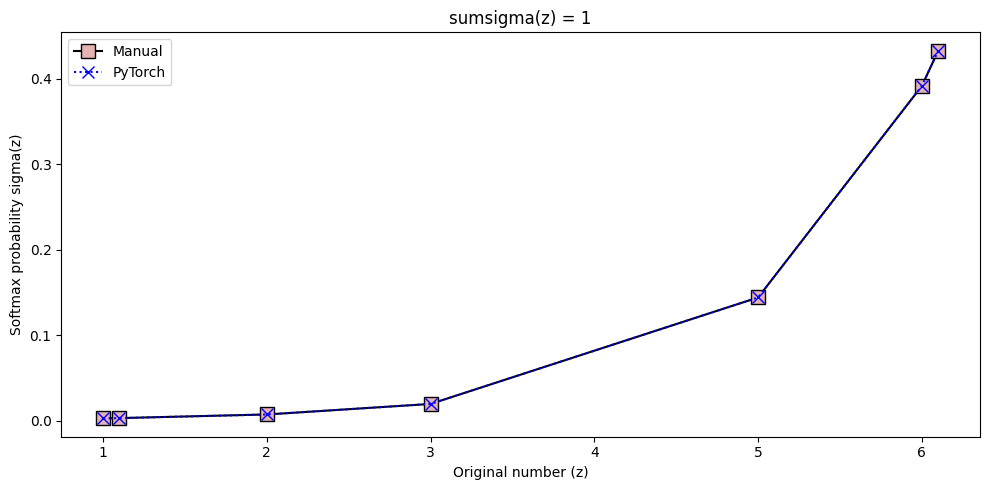

In [7]:

# compare
plt.figure(figsize=(10,5))

plt.plot(z,sm,'ks-',markerfacecolor=[.9,.7,.7],markersize=10,label='Manual')
plt.plot(z,zTorch_sm,'bx:',markersize=8,label='PyTorch')
plt.legend()

plt.gca().set(xlabel='Original number (z)',ylabel='Softmax probability sigma(z)',
              title='sumsigma(z) = %g' %np.sum(sm))

plt.tight_layout()
plt.savefig('ch4_proj16_part1.png')
plt.show()

# Part_2:Temperature

## Task_1
- create a PyTorch tensor comprising 55 linearly spaced numbers from-5 to 5. Transform that tensor into softmax probabilities using four
temperature values (.3, .6, 1, 1.4), and visualize the results as in
Figure 4.3.

In [9]:
x=torch.linspace(-5,5,55)
for i,temp in enumerate([0.3,0.6,1,1.4]):
  sm=F.softmax(x/temp,dim=-1)
  print(f"{i}={sm}")

0=tensor([1.5376e-15, 2.8505e-15, 5.2845e-15, 9.7968e-15, 1.8162e-14, 3.3670e-14,
        6.2421e-14, 1.1572e-13, 2.1454e-13, 3.9772e-13, 7.3734e-13, 1.3669e-12,
        2.5341e-12, 4.6980e-12, 8.7096e-12, 1.6147e-11, 2.9934e-11, 5.5494e-11,
        1.0288e-10, 1.9073e-10, 3.5359e-10, 6.5551e-10, 1.2152e-09, 2.2529e-09,
        4.1766e-09, 7.7430e-09, 1.4355e-08, 2.6612e-08, 4.9335e-08, 9.1462e-08,
        1.6956e-07, 3.1435e-07, 5.8276e-07, 1.0804e-06, 2.0029e-06, 3.7131e-06,
        6.8837e-06, 1.2762e-05, 2.3659e-05, 4.3860e-05, 8.1312e-05, 1.5074e-04,
        2.7946e-04, 5.1809e-04, 9.6048e-04, 1.7806e-03, 3.3011e-03, 6.1198e-03,
        1.1345e-02, 2.1033e-02, 3.8993e-02, 7.2288e-02, 1.3401e-01, 2.4845e-01,
        4.6059e-01])
1=tensor([1.5343e-08, 2.0891e-08, 2.8445e-08, 3.8729e-08, 5.2733e-08, 7.1800e-08,
        9.7761e-08, 1.3311e-07, 1.8124e-07, 2.4677e-07, 3.3599e-07, 4.5748e-07,
        6.2289e-07, 8.4812e-07, 1.1548e-06, 1.5723e-06, 2.1408e-06, 2.9149e-06,
        3.9688e

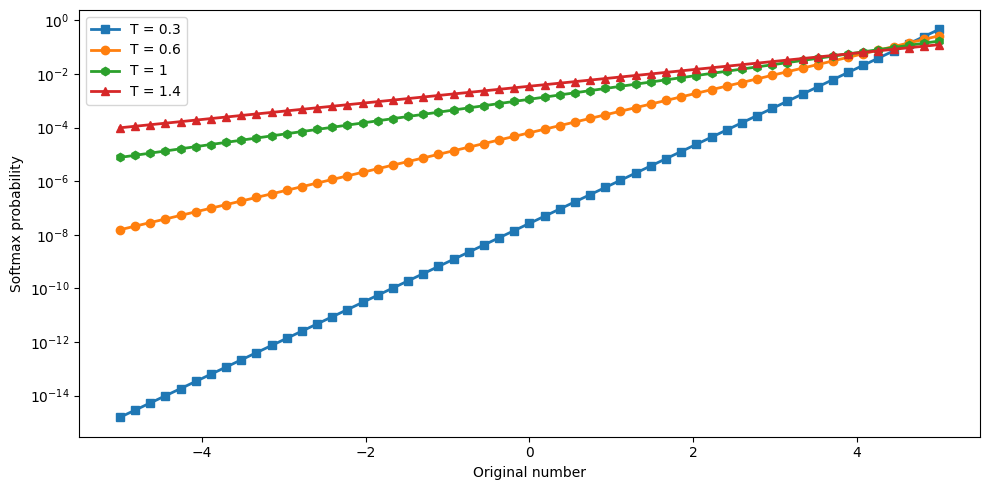

In [14]:
x = torch.linspace(-5,5,55)

shapes = 'soh^'

plt.figure(figsize=(10,5))
for i,temp in enumerate([.3,.6,1,1.4]):
  sm = F.softmax(x/temp,dim=-1)
  plt.plot(x,sm,shapes[i]+'-',linewidth=2,label='T = %g' %temp)

plt.legend()
plt.gca().set(xlabel='Original number',ylabel='Softmax probability')
plt.yscale('log')

plt.tight_layout()
plt.show()

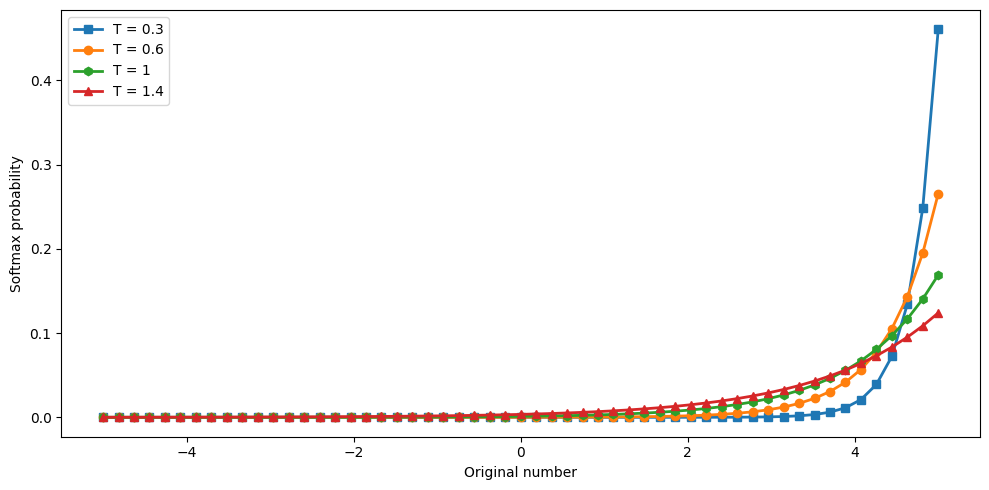

In [13]:
x = torch.linspace(-5,5,55)

shapes = 'soh^'

plt.figure(figsize=(10,5))
for i,temp in enumerate([.3,.6,1,1.4]):
  sm = F.softmax(x/temp,dim=-1)
  plt.plot(x,sm,shapes[i]+'-',linewidth=2,label='T = %g' %temp)

plt.legend()
plt.gca().set(xlabel='Original number',ylabel='Softmax probability')
# plt.yscale('log')

plt.tight_layout()
plt.show()